<a href="https://colab.research.google.com/github/jluzande/computer-vision-projects/blob/main/lab_7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import time
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
from scipy import ndimage as ndi
from skimage import data, segmentation, feature, measure
from skimage.color import label2rgb

def show(images, titles, cmap='gray', figsize=(16, 4)):
    n = len(images)
    plt.figure(figsize=figsize)
    for i, (im, t) in enumerate(zip(images, titles)):
        plt.subplot(1, n, i + 1)
        plt.imshow(im, cmap=cmap if im.ndim == 2 else None)
        plt.title(t); plt.axis('off')
    plt.tight_layout(); plt.show()

timings = {}   # filled in as each method runs

## 0. Load the image
We use the built-in **coins** image (grayscale, uneven lighting, touching objects), which works well for the first three methods. To use your own image, uncomment the upload lines.

Image shape: (303, 384)


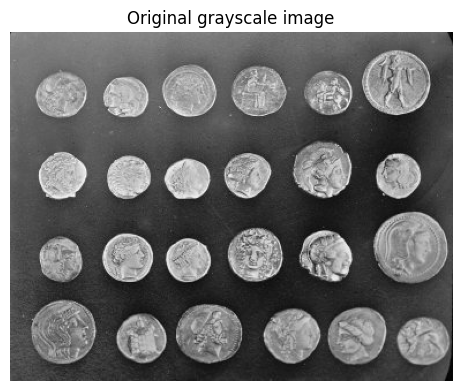

In [2]:
gray = data.coins()          # 303 x 384 grayscale

# --- OPTIONAL: use your own image ---
# from google.colab import files
# up = files.upload()
# gray = cv2.imread(list(up.keys())[0], cv2.IMREAD_GRAYSCALE)

print('Image shape:', gray.shape)
show([gray], ['Original grayscale image'], figsize=(5, 4))

Otsu threshold value: 104.0


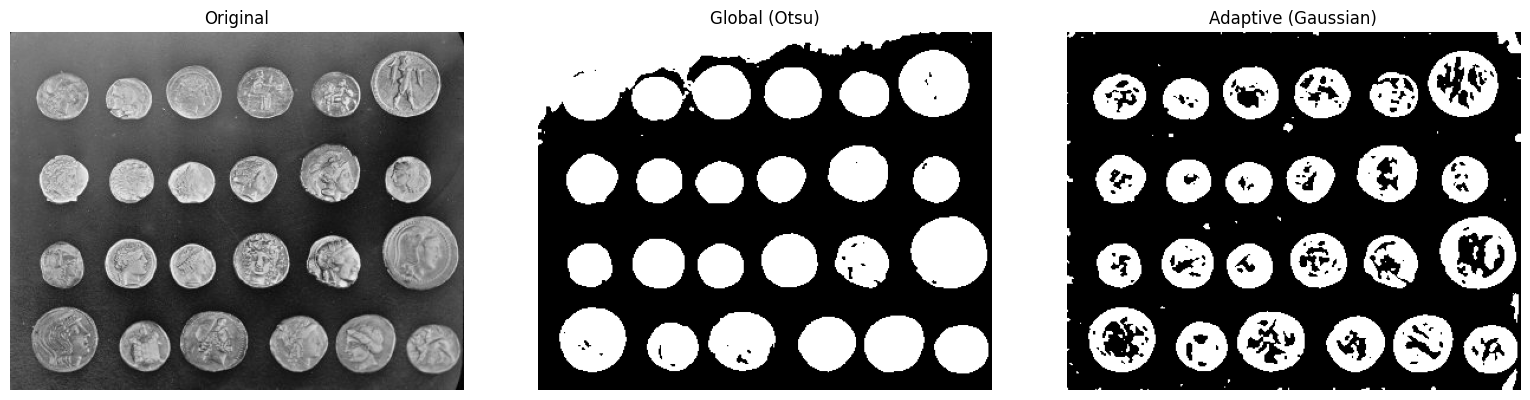

In [3]:
blur = cv2.GaussianBlur(gray, (5, 5), 0)

# Global thresholding (Otsu)
t0 = time.time()
otsu_t, otsu = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
timings['Thresholding (Otsu)'] = time.time() - t0

# Adaptive thresholding (handles non-uniform illumination)
t0 = time.time()
adaptive = cv2.adaptiveThreshold(blur, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                 cv2.THRESH_BINARY, blockSize=51, C=-5)
timings['Thresholding (Adaptive)'] = time.time() - t0

print('Otsu threshold value:', otsu_t)
show([gray, otsu, adaptive], ['Original', 'Global (Otsu)', 'Adaptive (Gaussian)'])

**Observation:** Otsu picks one threshold for the whole image, so uneven lighting leaves noise or misses part of the objects. Adaptive thresholding computes a local threshold and handles the lighting better, but it can add noise in flat areas.  
**Advantages / limitations:** Fast and simple, best for high-contrast images; it ignores spatial information and fails on complex or low-contrast scenes.

## 2. Region-Based Segmentation

Seed point (row, col): (np.int64(0), np.int64(0))


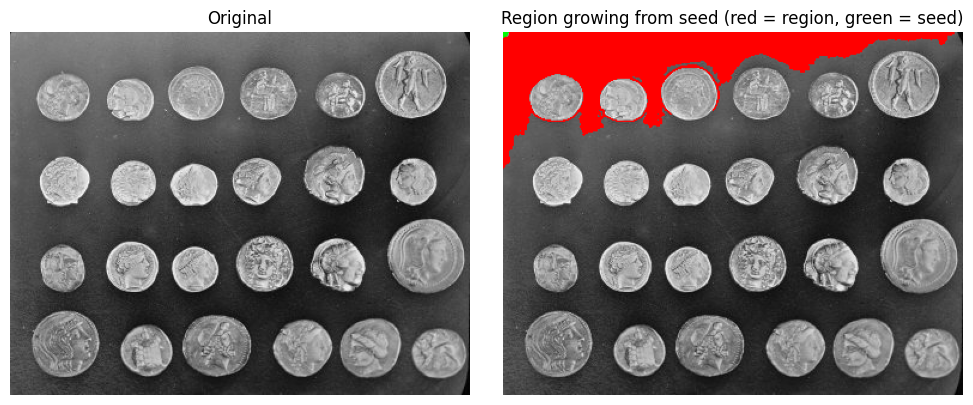

In [4]:
def region_growing(img, seed, tol=20):
    h, w = img.shape
    seg = np.zeros((h, w), dtype=bool)
    seed_val = float(img[seed])
    q = deque([seed]); seg[seed] = True
    while q:
        r, c = q.popleft()
        for dr, dc in ((1,0),(-1,0),(0,1),(0,-1)):
            nr, nc = r + dr, c + dc
            if 0 <= nr < h and 0 <= nc < w and not seg[nr, nc]:
                if abs(float(img[nr, nc]) - seed_val) <= tol:
                    seg[nr, nc] = True
                    q.append((nr, nc))
    return seg

mask_otsu = ndi.binary_fill_holes(cv2.morphologyEx(otsu, cv2.MORPH_OPEN, np.ones((3,3), np.uint8)) > 0)
dist = ndi.distance_transform_edt(mask_otsu)
seed = np.unravel_index(np.argmax(dist), dist.shape)
print('Seed point (row, col):', seed)

t0 = time.time()
grown = region_growing(blur, seed, tol=20)
timings['Region growing'] = time.time() - t0

overlay = cv2.cvtColor(gray, cv2.COLOR_GRAY2RGB)
overlay[grown] = (255, 0, 0)
cv2.circle(overlay, (seed[1], seed[0]), 4, (0, 255, 0), -1)
show([gray, overlay], ['Original', 'Region growing from seed (red = region, green = seed)'], figsize=(10, 4))

### 2b. Watershed (separates touching objects)


Objects found by watershed: 30


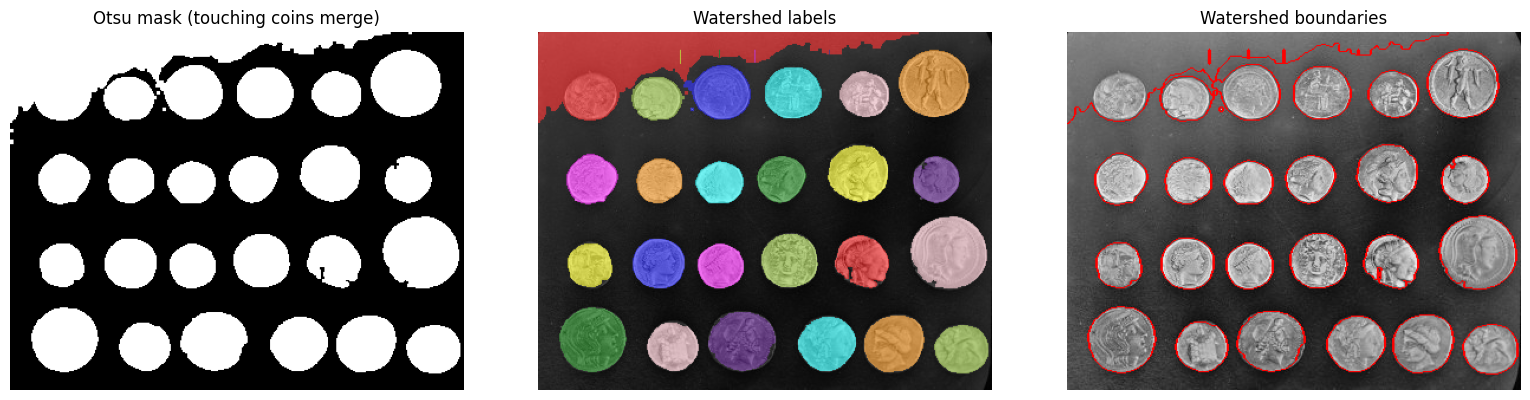

In [5]:
t0 = time.time()
coords = feature.peak_local_max(dist, min_distance=15, labels=measure.label(mask_otsu))
markers = np.zeros(dist.shape, dtype=int)
for i, (r, c) in enumerate(coords, start=1):
    markers[r, c] = i
ws_labels = segmentation.watershed(-dist, markers, mask=mask_otsu)
timings['Watershed'] = time.time() - t0

print('Objects found by watershed:', ws_labels.max())
show([mask_otsu, label2rgb(ws_labels, image=gray, bg_label=0, alpha=0.5),
      segmentation.mark_boundaries(gray, ws_labels, color=(1, 0, 0))],
     ['Otsu mask (touching coins merge)', 'Watershed labels', 'Watershed boundaries'])

**Observation:** Watershed splits touching coins that thresholding merged into one blob. Too many markers cause **over-segmentation**; too few cause merged objects (tune `min_distance`).

## 3. Edge-Based Segmentation

Closed contours found: 24


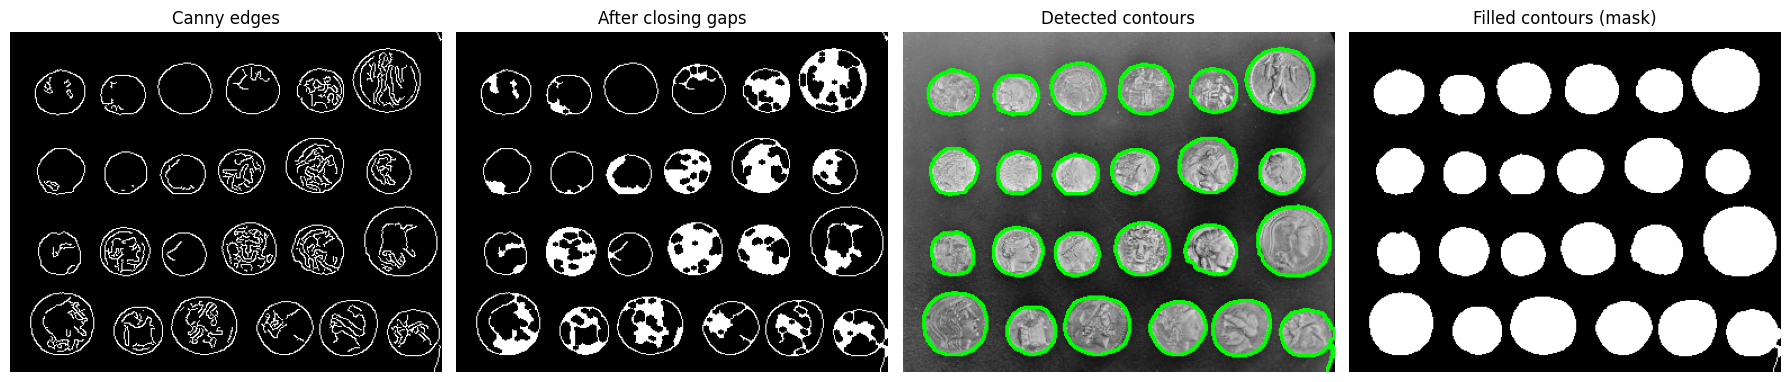

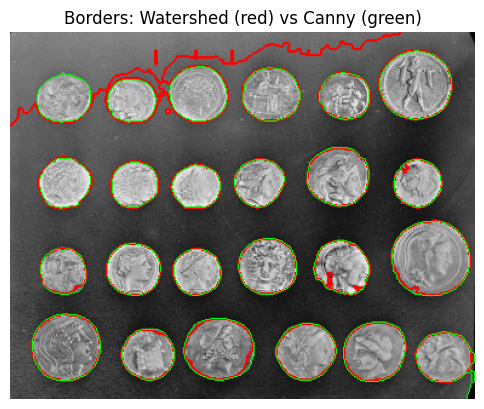

In [6]:
t0 = time.time()
edges = cv2.Canny(blur, 50, 150)
closed = cv2.morphologyEx(edges, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5)))
contours, _ = cv2.findContours(closed, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
contours = [c for c in contours if cv2.contourArea(c) > 300]
canny_mask = np.zeros_like(gray)
cv2.drawContours(canny_mask, contours, -1, 255, thickness=cv2.FILLED)
timings['Edge-based (Canny)'] = time.time() - t0

contour_img = cv2.cvtColor(gray, cv2.COLOR_GRAY2RGB)
cv2.drawContours(contour_img, contours, -1, (0, 255, 0), 2)
print('Closed contours found:', len(contours))
show([edges, closed, contour_img, canny_mask],
     ['Canny edges', 'After closing gaps', 'Detected contours', 'Filled contours (mask)'], figsize=(18, 4))

wb = segmentation.find_boundaries(ws_labels)
cmp_img = cv2.cvtColor(gray, cv2.COLOR_GRAY2RGB)
cmp_img[wb] = (255, 0, 0)                                   # watershed = red
cv2.drawContours(cmp_img, contours, -1, (0, 255, 0), 1)     # Canny = green
plt.figure(figsize=(6, 5)); plt.imshow(cmp_img); plt.axis('off')
plt.title('Borders: Watershed (red) vs Canny (green)'); plt.show()

**Observation:** Canny gives sharp, precise borders where the edges are clear, but gaps in edges (noise, weak contrast) leave contours unclosed. Region-based methods always return closed regions but their borders are less precise.

## 4. Semantic Segmentation (pre-trained DeepLabV3, PASCAL VOC classes)

Downloading: "https://download.pytorch.org/models/deeplabv3_resnet50_coco-cd0a2569.pth" to /root/.cache/torch/hub/checkpoints/deeplabv3_resnet50_coco-cd0a2569.pth


100%|██████████| 161M/161M [00:01<00:00, 94.6MB/s]


Classes detected: ['background', 'person']


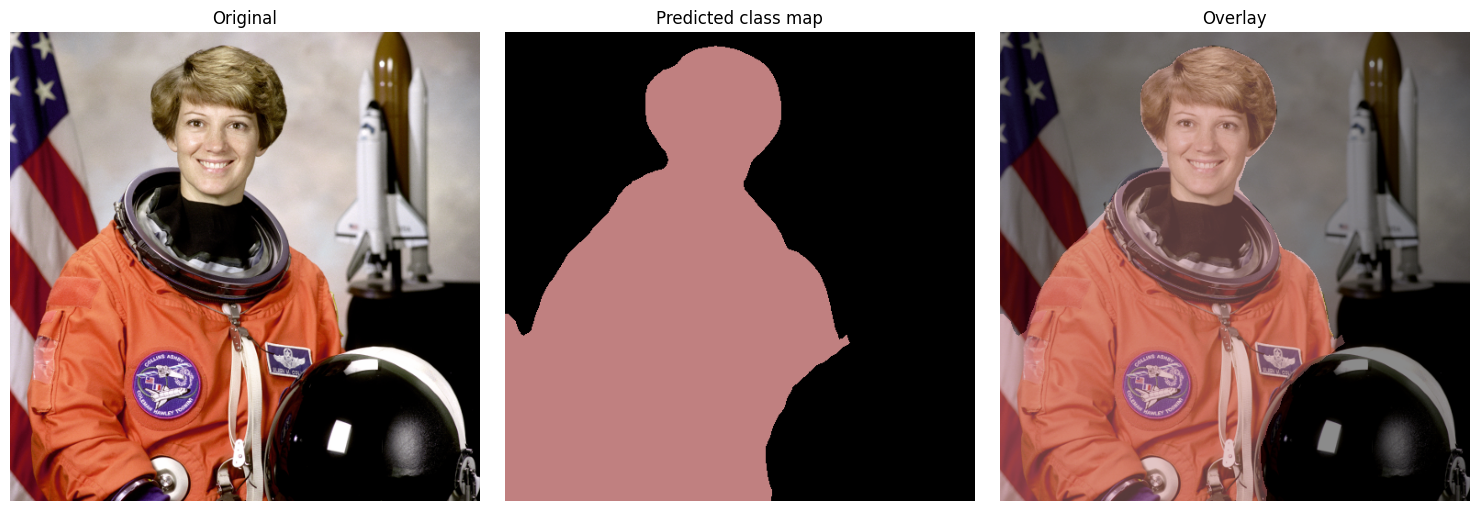

In [7]:
import torch
from torchvision import models, transforms
from PIL import Image

device = 'cuda' if torch.cuda.is_available() else 'cpu'
weights = models.segmentation.DeepLabV3_ResNet50_Weights.DEFAULT
model = models.segmentation.deeplabv3_resnet50(weights=weights).to(device).eval()

# Natural image with a person (built in). Replace with your own photo if you want.
rgb = data.astronaut()
# rgb = np.array(Image.open('your_photo.jpg').convert('RGB'))

prep = transforms.Compose([transforms.ToTensor(),
                           transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])
x = prep(rgb).unsqueeze(0).to(device)

t0 = time.time()
with torch.no_grad():
    out = model(x)['out'][0]
pred = out.argmax(0).cpu().numpy()
timings['Semantic (DeepLabV3)'] = time.time() - t0

VOC = ['background','aeroplane','bicycle','bird','boat','bottle','bus','car','cat','chair','cow',
       'diningtable','dog','horse','motorbike','person','pottedplant','sheep','sofa','train','tvmonitor']

def voc_cmap(N=256):
    cmap = np.zeros((N, 3), dtype=np.uint8)
    for i in range(N):
        c, r, g, b = i, 0, 0, 0
        for j in range(8):
            r |= ((c >> 0) & 1) << (7 - j); g |= ((c >> 1) & 1) << (7 - j); b |= ((c >> 2) & 1) << (7 - j)
            c >>= 3
        cmap[i] = [r, g, b]
    return cmap

color_mask = voc_cmap()[pred]
blend = (0.55 * rgb + 0.45 * color_mask).astype(np.uint8)
found = [VOC[i] for i in np.unique(pred)]
print('Classes detected:', found)
show([rgb, color_mask, blend], ['Original', 'Predicted class map', 'Overlay'], figsize=(15, 5))

**Observation:** Every pixel gets a class label (person, background, etc.), so the model understands *what* is in the scene, not just where regions differ. The cost is a large model, pre-training on labeled data, and much more computation.

In [8]:
## 5. Analysis

,Otsu,Adaptive,Watershed,Canny contours
Otsu,1.000,0.651,0.994,0.778
Adaptive,0.651,1.000,0.649,0.775
Watershed,0.994,0.649,1.000,0.782
Canny contours,0.778,0.775,0.782,1.000


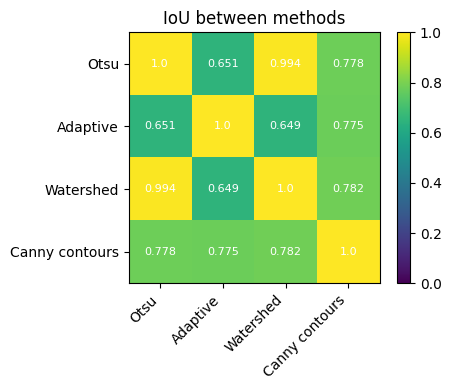

In [9]:
def iou(a, b):
    a, b = a.astype(bool), b.astype(bool)
    return (a & b).sum() / max((a | b).sum(), 1)

masks = {
    'Otsu': otsu > 0,
    'Adaptive': adaptive > 0,
    'Watershed': ws_labels > 0,
    'Canny contours': canny_mask > 0,
}
# masks['Ground truth'] = your_gt_mask > 0

names = list(masks)
iou_df = pd.DataFrame([[iou(masks[a], masks[b]) for b in names] for a in names],
                      index=names, columns=names).round(3)
display(iou_df)

plt.figure(figsize=(5, 4)); plt.imshow(iou_df.values, cmap='viridis', vmin=0, vmax=1)
plt.xticks(range(len(names)), names, rotation=45, ha='right'); plt.yticks(range(len(names)), names)
for i in range(len(names)):
    for j in range(len(names)):
        plt.text(j, i, iou_df.values[i, j], ha='center', va='center', color='w', fontsize=8)
plt.colorbar(); plt.title('IoU between methods'); plt.tight_layout(); plt.show()

,Time (seconds)
Edge-based (Canny),0.0317
Thresholding (Otsu),0.0361
Thresholding (Adaptive),0.0690
Region growing,0.1373
Watershed,0.2009
Semantic (DeepLabV3),7.8889


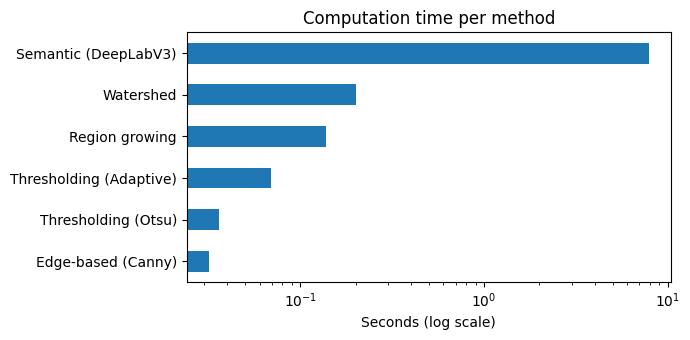

In [10]:
time_df = pd.DataFrame({'Time (seconds)': timings}).round(4).sort_values('Time (seconds)')
display(time_df)
time_df.plot.barh(legend=False, figsize=(7, 3.5)); plt.xscale('log')
plt.xlabel('Seconds (log scale)'); plt.title('Computation time per method'); plt.tight_layout(); plt.show()

### 5c. Use cases, limitations, and complexity
| Technique | Best use case | Limitation | Complexity |
|---|---|---|---|
| Thresholding | Simple, high-contrast images (documents, binary-like objects) | Fails with uneven lighting or low contrast; ignores spatial information | Very low |
| Region-based | Objects with uniform texture; touching objects (watershed) | Seed selection, tolerance tuning, over-segmentation | Low to medium |
| Edge-based | Objects with clear, sharp boundaries | Noise sensitive; edges often not closed | Low |
| Semantic | Complex natural scenes, when class labels are needed | Needs labeled data, large model, heavy computation | High |

**Implementation challenges (edit with your own experience):** ____________

## Question
**Explain the differences between thresholding, region-based, edge-based, and semantic segmentation. Provide one advantage and one limitation for each method.**

| Technique | How it works | Advantage | Limitation |
|---|---|---|---|
| **Thresholding** | Splits pixels into foreground/background by intensity (global like Otsu, or adaptive) | Simple and very fast | Fails on low-contrast images or uneven lighting; ignores spatial information |
| **Region-based** | Groups neighboring pixels by similarity (region growing, watershed) | Produces connected, closed regions; watershed separates touching objects | Sensitive to seed selection and noise; watershed often over-segments |
| **Edge-based** | Finds sudden intensity changes (e.g., Canny) and uses them to outline objects | Precise boundaries when edges are clear | Sensitive to noise; edges are often broken or not closed |
| **Semantic** | A deep learning model labels every pixel with a class | Understands the scene; handles complex natural images | Needs large labeled datasets and heavy computation |

The first three use pixel properties such as intensity and edges. Semantic segmentation learns what objects are, so it labels pixels by meaning.

## Conclusion

In this activity, I applied thresholding, region-based, edge-based, and semantic segmentation. Thresholding was the fastest and worked well on the high-contrast coins, but global thresholding was affected by uneven lighting and adaptive thresholding handled it better. Region growing depended on the seed point and tolerance, while watershed separated touching coins but could over-segment. Canny gave precise boundaries but left gaps that needed morphological closing. DeepLabV3 labeled every pixel by class and understood the scene best, but it was the slowest and needed a pre-trained model. Overall, the best technique depends on the image: simple methods suit simple, high-contrast images, while semantic segmentation suits complex scenes where object meaning matters.